# The baseline every world model must beat

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/wnukmat/robot-learning-notebooks/blob/main/notebooks/3_robot_learning/07_world_model_baselines.ipynb) &nbsp; Guide note: [guide-world-models](https://www.matthewwnuk.com/guide-world-models.html)

A world model predicts future camera frames. Before judging one, it helps to know how well the most
trivial predictor does: output the current frame unchanged. This notebook measures that on real robot
video and shows why whole-image scores flatter almost any model.

In [1]:
# Setup. On Colab this installs the small helper package; where it is already installed it does nothing.
import importlib.util, subprocess, sys
if importlib.util.find_spec("guide_utils") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/wnukmat/robot-learning-notebooks"])

In [2]:
import numpy as np, matplotlib.pyplot as plt
from guide_utils import data, style
style.use()
seq = data.libero_sequences(); V = seq["scene"].astype(np.float32); print("clips:", V.shape, "= (episode, frame, height, width, colour), 10 frames per second")

clips: (12, 60, 128, 128, 3) = (episode, frame, height, width, colour), 10 frames per second


## How much of a robot video actually changes?

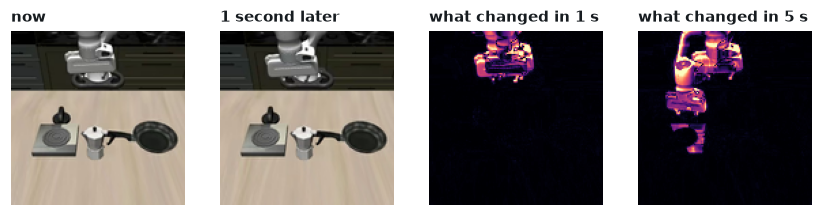

In [3]:
e = 6; now, later1, later5 = V[e, 0], V[e, 10], V[e, 50]; fig, ax = plt.subplots(1, 4, figsize=(9.4, 2.6))
for a, im, t in zip(ax, (now, later1, np.abs(later1 - now).max(-1), np.abs(later5 - now).max(-1)), ("now", "1 second later", "what changed in 1 s", "what changed in 5 s")):
    a.imshow(im.astype(np.uint8) if im.ndim == 3 else im, cmap=None if im.ndim == 3 else "magma", vmin=0 if im.ndim == 2 else None, vmax=160 if im.ndim == 2 else None); a.set_title(t, fontsize=10); style.bare(a)
plt.show()

The table and the background do not move. Only the arm and the object it touches do.

## Scoring "predict no change"

PSNR is the usual image-similarity score: 10 log10(255^2 / mean squared error), in decibels.

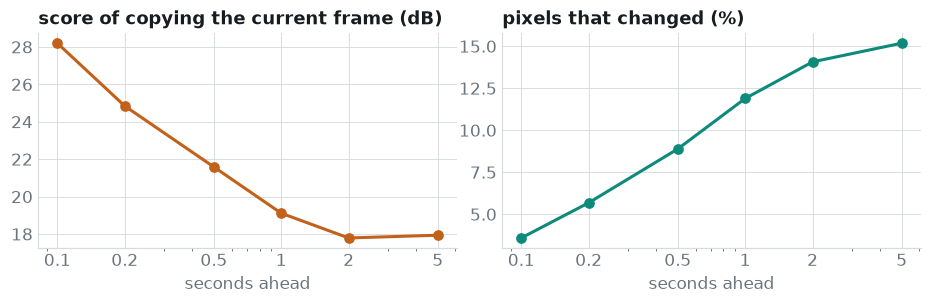

 0.1 s ahead: copying scores 28.2 dB, 4% of pixels changed
 0.2 s ahead: copying scores 24.8 dB, 6% of pixels changed
 0.5 s ahead: copying scores 21.6 dB, 9% of pixels changed
 1.0 s ahead: copying scores 19.1 dB, 12% of pixels changed
 2.0 s ahead: copying scores 17.8 dB, 14% of pixels changed
 5.0 s ahead: copying scores 17.9 dB, 15% of pixels changed


In [4]:
def psnr(a, b): return 10 * np.log10(255 ** 2 / np.maximum(((a - b) ** 2).mean((-1, -2, -3)), 1e-6))
horizons = [1, 2, 5, 10, 20, 50]; starts = range(0, 9)
copy = [np.mean([psnr(V[:, s], V[:, s + h]) for s in starts]) for h in horizons]; changed = [np.mean([(np.abs(V[:, s + h] - V[:, s]).max(-1) > 20).mean() for s in starts]) * 100 for h in horizons]
fig, ax = plt.subplots(1, 2, figsize=(8.6, 2.9)); sec = np.array(horizons) / 10
ax[0].plot(sec, copy, marker="o", color=style.ORANGE); ax[0].set_title("score of copying the current frame (dB)"); ax[1].plot(sec, changed, marker="o"); ax[1].set_title("pixels that changed (%)")
for a in ax: a.set_xscale("log"); a.set_xticks(sec); a.set_xticklabels([f"{v:g}" for v in sec]); a.set_xlabel("seconds ahead")
plt.tight_layout(); plt.show()
for h, c, ch in zip(horizons, copy, changed): print(f"{h / 10:4.1f} s ahead: copying scores {c:.1f} dB, {ch:.0f}% of pixels changed")

## A slightly less trivial predictor

Extrapolate linearly from the last two frames. It does better for a step or two and then worse, because
robot motion does not continue in a straight line.

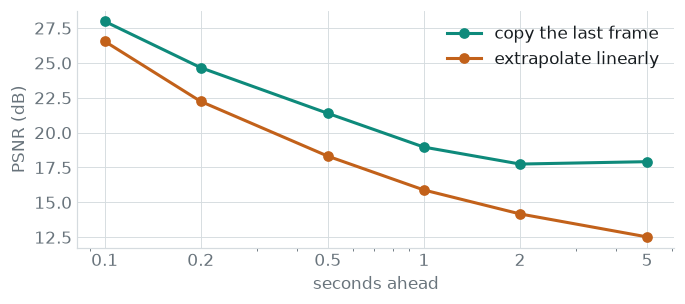

In [5]:
lin = [np.mean([psnr(np.clip(V[:, s + 1] + h * (V[:, s + 1] - V[:, s]), 0, 255), V[:, s + 1 + h]) for s in starts]) for h in horizons]
cp = [np.mean([psnr(V[:, s + 1], V[:, s + 1 + h]) for s in starts]) for h in horizons]
plt.figure(figsize=(7, 2.8)); plt.plot(sec, cp, marker="o", label="copy the last frame"); plt.plot(sec, lin, marker="o", label="extrapolate linearly"); plt.xscale("log"); plt.xticks(sec, [f"{v:g}" for v in sec]); plt.xlabel("seconds ahead"); plt.ylabel("PSNR (dB)"); plt.legend(); plt.show()

## Score only what moves

Restrict the error to the pixels that changed, and the copying baseline is exposed.

In [6]:
def psnr_masked(pred, true, ref):
    mask = (np.abs(true - ref).max(-1) > 20)[..., None]; mse = (((pred - true) ** 2) * mask).sum((-1, -2, -3)) / np.maximum(mask.sum((-1, -2, -3)) * 3, 1); return 10 * np.log10(255 ** 2 / np.maximum(mse, 1e-6))
for h in (1, 10, 50): print(f"{h / 10:4.1f} s ahead: whole image {psnr(V[:, 0], V[:, h]).mean():.1f} dB   moving region only {psnr_masked(V[:, 0], V[:, h], V[:, 0]).mean():.1f} dB")

 0.1 s ahead: whole image 28.9 dB   moving region only 13.9 dB
 1.0 s ahead: whole image 19.7 dB   moving region only 10.0 dB
 5.0 s ahead: whole image 18.1 dB   moving region only 9.6 dB


A reported image-similarity score means little without the copying baseline beside it, and less still
if it is averaged over a background that never moves.

## Things to try

- Repeat with the wrist camera, `seq["wrist"]`. Why is the baseline so much weaker there?
- Blur the copied frame slightly. Does the score go up? What does that say about the metric?
- Fit a per-pixel linear predictor from the last three frames by least squares.